<a href="https://colab.research.google.com/github/neysazefanya/Pengujian-Validitas-dan-Reabilitas---Probstat/blob/main/uji_validitas_reabilitas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install pingouin factor_analyzer -q

In [2]:
!pip install --upgrade numpy scipy pingouin factor_analyzer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 62.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 27.8 MB/s  0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scipy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [4]:
import pandas as pd, numpy as np, pingouin as pg
from scipy import stats
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [5]:
from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban) (1).xlsx to Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban) (1) (1).xlsx
File terbaca: Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban) (1) (1).xlsx


In [6]:
# Kolom 1-6 = Timestamp, Kelas, Jenis Kelamin, jml platform AI, jml AI berbayar, durasi gadget
# Butir skala Likert baru mulai dari kolom ke-7
JUMLAH_KOLOM_DEMOGRAFI = 6

df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 30
Jumlah butir     : 29
Data kosong      : 0


In [7]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.apply(lambda kol: kol.astype(str).str.strip().map(skala))

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI hampir setiap kali mendapatkan tugas atau projek kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari penyelesaian soal atau permasalahan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi saat mengerjakan tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk memahami materi kuliah yang belum saya kuasai.],"Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk menyusun atau memperbaiki tulisan dalam tugas kuliah, misalnya laporan atau makalah.]",Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk membuat atau memperbaiki kode program pada tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan lebih dari satu platform AI untuk menyelesaikan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah tanpa bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung langsung mengikuti jawaban AI tanpa mempertimbangkan sumber lain.],...,Kebiasaan penggunaan teknologi digital [Konsentrasi saya mudah terganggu oleh gadget ketika sedang mengerjakan tugas kuliah.],Prokrastinasi akademik [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik [Saya sering menunda tugas karena merasa tugas tersebut dapat diselesaikan dengan cepat menggunakan AI.],Prokrastinasi akademik [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik [Saya sering harus mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas dengan hasil tugas yang dikerjakan terburu-buru menjelang deadline.],Respon emosional [Saya merasa gelisah ketika mengingat tugas yang belum saya kerjakan.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,2,4,4,4,4,4,4,2,2,2,...,1,2,2,2,2,4,4,4,4,4
1,4,4,4,4,4,4,4,4,2,2,...,4,4,4,4,4,4,4,4,4,4
2,5,5,5,5,5,5,5,5,4,4,...,5,2,5,5,5,5,5,5,5,5
3,4,5,5,5,4,4,4,4,2,2,...,4,4,2,5,4,4,4,2,5,4
4,5,4,5,5,5,4,5,5,4,1,...,4,1,2,1,2,5,5,4,4,4


In [8]:
import re

dimensi = {}
for kolom in butir.columns:
    match = re.match(r"^(.*?) \[", kolom)
    if match:
        nama = match.group(1)
        dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


In [9]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (\u03b1=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })
tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 30 | r tabel (α=0,05; df=28) = 0.361


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.790,0.668,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.691,0.585,0.0000,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.627,0.481,0.0002,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.554,0.424,0.0015,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.722,0.495,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.800,0.723,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.654,0.548,0.0001,Valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.710,0.605,0.0000,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.780,0.685,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.710,0.617,0.0000,Valid


In [10]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))


def kategori(a):
    return (
        "Sangat baik"
        if a >= 0.90
        else "Baik" if a >= 0.80 else "Reliabel" if a >= 0.70 else "Tidak reliabel"
    )


hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(
                    cronbach_alpha(x.drop(columns=kolom)), 3
                ),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.799,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.886,Baik
2,Kebiasaan penggunaan teknologi digital,6,0.890,Baik
3,Prokrastinasi akademik,4,0.860,Baik
4,Respon emosional,5,0.928,Sangat baik


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.744
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.768
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.782
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.791
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.808
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.746
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.775
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.879
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.869
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.877


## Pengecekan Distribusi Data per Dimensi

Bagian ini melengkapi uji validitas dan reliabilitas dengan pemeriksaan **bentuk sebaran jawaban** pada setiap dimensi, secara visual (grafik), frekuensi, serta skewness dan kurtosis.

Skor dimensi tiap responden dihitung sebagai *rata-rata* butir dalam dimensi itu (skala 1-5), sehingga dimensi dengan jumlah butir berbeda tetap sebanding.

| Ukuran | Arti singkat | Cara membaca |
|---|---|---|
| **Skewness** (kemiringan) | Apakah sebaran miring ke satu sisi | 0 = simetris; negatif = jawaban menumpuk di nilai tinggi; positif = menumpuk di nilai rendah |
| **Kurtosis** (excess) | Apakah sebaran lebih runcing/landai dari kurva normal | 0 = seperti normal; positif = runcing; negatif = landai |

Pedoman umum pada tabel: |skewness| < 0,5 dianggap simetris, 0,5 sampai 1 miring sedang, > 1 miring kuat; kurtosis dalam rentang -0,5 sampai 0,5 dianggap mendekati normal.

In [11]:
import matplotlib.pyplot as plt
import textwrap

def arti_skew(s):
    if abs(s) < 0.5: return "Simetris"
    arah = "kiri (menumpuk di nilai tinggi)" if s < 0 else "kanan (menumpuk di nilai rendah)"
    return ("Miring sedang ke " if abs(s) <= 1 else "Miring kuat ke ") + arah

def arti_kurt(k):
    if abs(k) <= 0.5: return "Mendekati normal"
    return "Runcing" if k > 0 else "Landai"

skor_dimensi = {}      # skor rata-rata per responden untuk tiap dimensi
hasil_distribusi = []
for nama, daftar in dimensi.items():
    rata = num[daftar].mean(axis=1)
    skor_dimensi[nama] = rata
    sk = stats.skew(rata, bias=False)
    ku = stats.kurtosis(rata, bias=False)   # excess kurtosis (normal = 0)
    hasil_distribusi.append({
        "Dimensi": nama,
        "Rata-rata": round(rata.mean(), 2),
        "SD": round(rata.std(ddof=1), 2),
        "Min": round(rata.min(), 2),
        "Maks": round(rata.max(), 2),
        "Skewness": round(sk, 3),
        "Arti skewness": arti_skew(sk),
        "Kurtosis": round(ku, 3),
        "Arti kurtosis": arti_kurt(ku),
    })
tabel_distribusi = pd.DataFrame(hasil_distribusi)
tabel_distribusi

,Dimensi,Rata-rata,SD,Min,Maks,Skewness,Arti skewness,Kurtosis,Arti kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,4.58,0.41,3.71,5.0,-0.526,Miring sedang ke kiri (menumpuk di nilai tinggi),-1.057,Landai
1,Aspek Psikologis penggunaan AI pada tugas atau...,2.86,1.11,1.00,5.0,0.018,Simetris,-0.690,Landai
2,Kebiasaan penggunaan teknologi digital,3.59,1.24,1.17,5.0,-0.487,Simetris,-1.015,Landai
3,Prokrastinasi akademik,3.04,1.38,1.00,5.0,-0.078,Simetris,-1.453,Landai
4,Respon emosional,4.14,1.16,1.00,5.0,-2.083,Miring kuat ke kiri (menumpuk di nilai tinggi),3.646,Runcing


In [12]:
# Tabel frekuensi jawaban per butir (jumlah responden) dan ringkasan per dimensi
label_skala = ["STS", "TS", "N", "S", "SS"]
frek_list = []
for nama, daftar in dimensi.items():
    for i, kolom in enumerate(daftar, 1):
        baris = {"Dimensi": nama, "Butir": f"B{i}"}
        for v, lab in enumerate(label_skala, 1):
            baris[lab] = int((num[kolom] == v).sum())
        frek_list.append(baris)
tabel_frekuensi = pd.DataFrame(frek_list)

print("Frekuensi jawaban per butir (jumlah responden):")
display(tabel_frekuensi)

# Persentase seluruh jawaban dalam tiap dimensi (gabungan semua butir)
ringkas = []
for nama, daftar in dimensi.items():
    nilai = num[daftar].values.ravel()
    baris = {"Dimensi": nama, "Total jawaban": len(nilai)}
    for v, lab in enumerate(label_skala, 1):
        baris[f"% {lab}"] = round((nilai == v).mean() * 100, 1)
    ringkas.append(baris)
tabel_persen = pd.DataFrame(ringkas)
print("\nPersentase jawaban gabungan per dimensi:")
display(tabel_persen)

Frekuensi jawaban per butir (jumlah responden):


,Dimensi,Butir,STS,TS,N,S,SS
0,Penggunaan AI pada tugas atau projek kuliah,B1,0,1,0,12,17
1,Penggunaan AI pada tugas atau projek kuliah,B2,0,0,0,10,20
2,Penggunaan AI pada tugas atau projek kuliah,B3,0,0,1,11,18
3,Penggunaan AI pada tugas atau projek kuliah,B4,0,0,0,9,21
4,Penggunaan AI pada tugas atau projek kuliah,B5,0,3,1,12,14
5,Penggunaan AI pada tugas atau projek kuliah,B6,0,0,0,11,19
6,Penggunaan AI pada tugas atau projek kuliah,B7,0,0,0,8,22
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,2,7,0,10,11
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,7,5,1,12,5
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,15,8,3,2,2



Persentase jawaban gabungan per dimensi:


,Dimensi,Total jawaban,% STS,% TS,% N,% S,% SS
0,Penggunaan AI pada tugas atau projek kuliah,210,0.0,1.9,1.0,34.8,62.4
1,Aspek Psikologis penggunaan AI pada tugas atau...,210,27.6,23.3,3.3,26.7,19.0
2,Kebiasaan penggunaan teknologi digital,180,15.6,17.8,0.0,25.6,41.1
3,Prokrastinasi akademik,120,25.0,25.0,0.8,19.2,30.0
4,Respon emosional,150,11.3,3.3,0.0,30.7,54.7


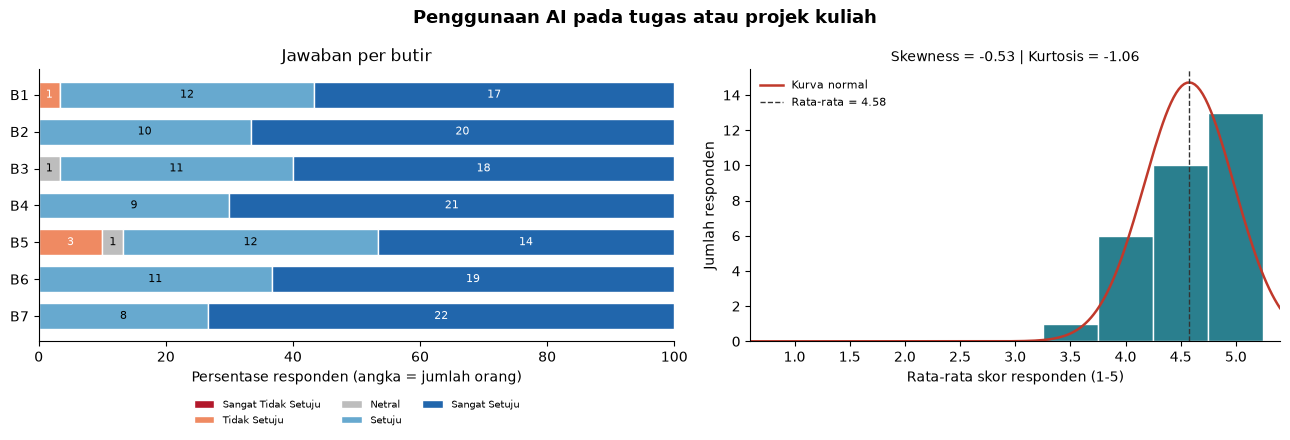

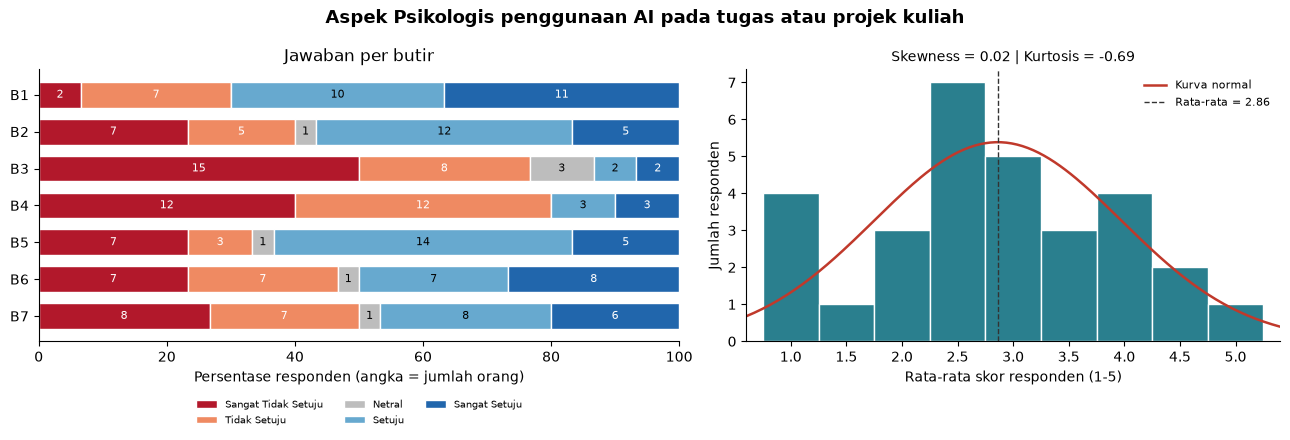

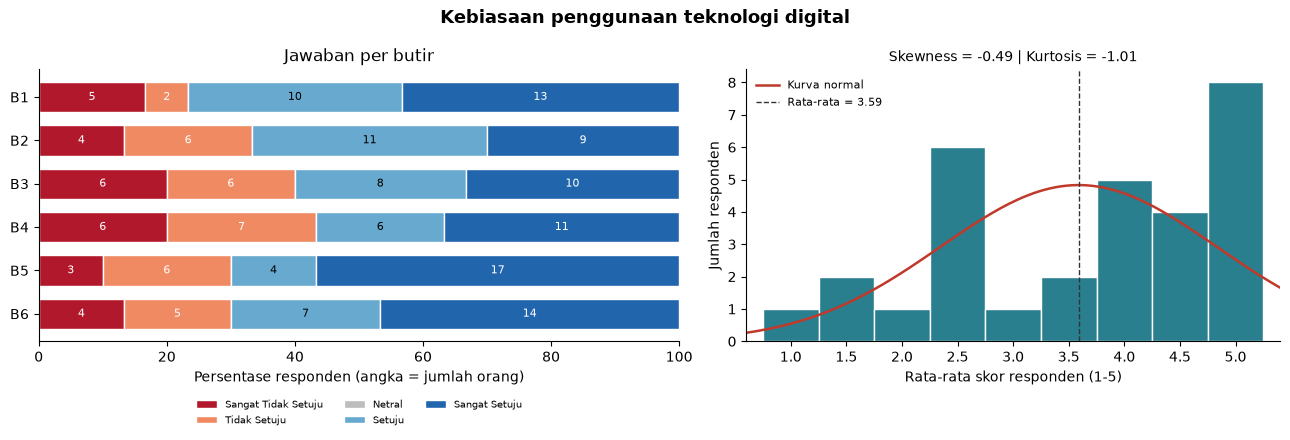

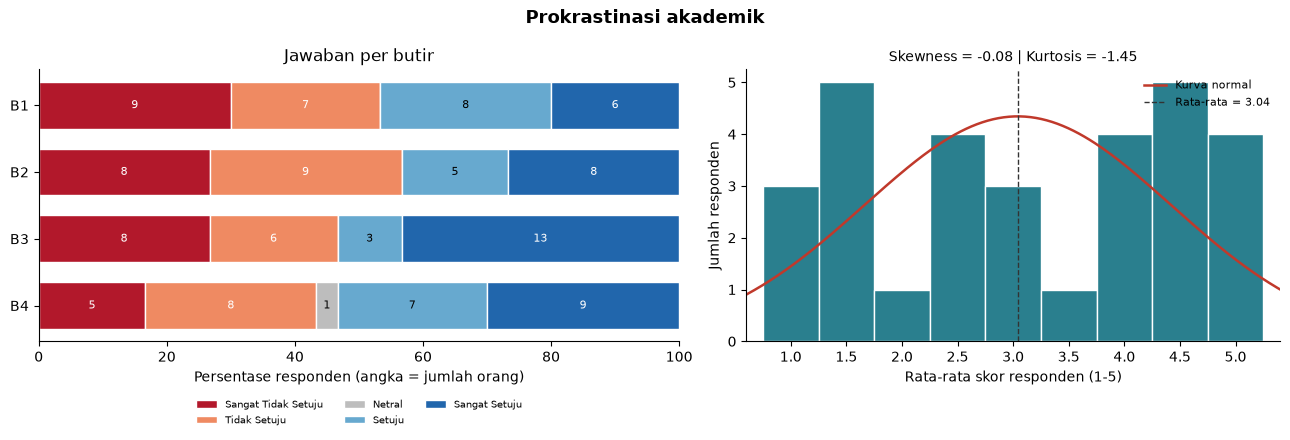

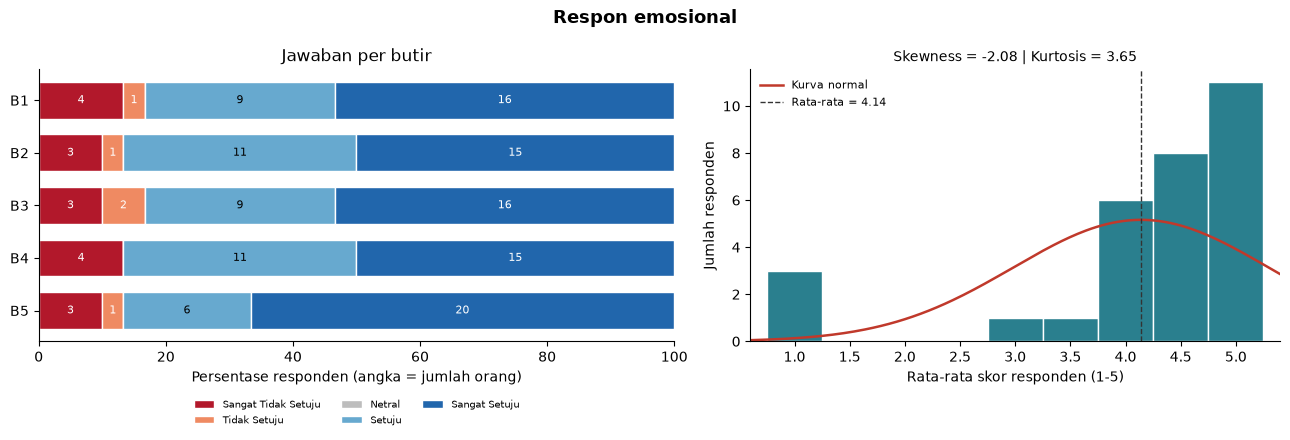

In [13]:
# Grafik distribusi per dimensi: (1) diagram batang jawaban per butir, (2) histogram rata-rata skor
warna = ["#B2182B", "#EF8A62", "#BDBDBD", "#67A9CF", "#2166AC"]
nama_skala = ["Sangat Tidak Setuju", "Tidak Setuju", "Netral", "Setuju", "Sangat Setuju"]

for nama, daftar in dimensi.items():
    k = len(daftar)
    rata = skor_dimensi[nama]
    sk, ku = stats.skew(rata, bias=False), stats.kurtosis(rata, bias=False)

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1.0]})
    fig.suptitle(textwrap.fill(nama, 90), fontsize=13, fontweight="bold")

    # (1) diagram batang bertumpuk (persentase), angka = jumlah responden
    kiri = np.zeros(k)
    for v in range(1, 6):
        jml = np.array([(num[c] == v).sum() for c in daftar])
        persen = jml / n * 100
        ax[0].barh(range(k), persen, left=kiri, color=warna[v - 1],
                   edgecolor="white", height=0.7, label=nama_skala[v - 1])
        for i in range(k):
            if jml[i] > 0:
                ax[0].text(kiri[i] + persen[i] / 2, i, str(jml[i]), ha="center", va="center",
                           fontsize=8, color="black" if v == 3 or v == 4 else "white")
        kiri += persen
    ax[0].set_yticks(range(k)); ax[0].set_yticklabels([f"B{i}" for i in range(1, k + 1)])
    ax[0].invert_yaxis(); ax[0].set_xlim(0, 100)
    ax[0].set_xlabel("Persentase responden (angka = jumlah orang)")
    ax[0].set_title("Jawaban per butir")
    ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=7.5, frameon=False)

    # (2) histogram rata-rata skor + kurva normal pembanding
    tepi = np.arange(0.75, 5.3, 0.5)
    ax[1].hist(rata, bins=tepi, color="#2A7F8E", edgecolor="white")
    xs = np.linspace(0.6, 5.4, 200)
    ax[1].plot(xs, stats.norm.pdf(xs, rata.mean(), rata.std(ddof=1)) * n * 0.5,
               color="#C0392B", lw=1.8, label="Kurva normal")
    ax[1].axvline(rata.mean(), color="#333", ls="--", lw=1, label=f"Rata-rata = {rata.mean():.2f}")
    ax[1].set_xlim(0.6, 5.4); ax[1].set_xticks(np.arange(1, 5.1, 0.5))
    ax[1].set_xlabel("Rata-rata skor responden (1-5)"); ax[1].set_ylabel("Jumlah responden")
    ax[1].set_title(f"Skewness = {sk:.2f} | Kurtosis = {ku:.2f}", fontsize=10)
    ax[1].legend(fontsize=8, frameon=False)

    for a in ax:
        a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

In [14]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_distribusi.to_excel(w, sheet_name="Distribusi Dimensi", index=False)
    tabel_frekuensi.to_excel(w, sheet_name="Frekuensi Butir", index=False)
    tabel_persen.to_excel(w, sheet_name="Persen Dimensi", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>